# Particle Swarm Optimization (PSO): experimental results

The experimental benchmark covers three variants of **Particle Swarm Optimization (PSO)** across standard benchmark functions in **10 dimensions ($D=10$)**:
- **Schwefel Function:** Highly multimodal and deceptive search landscape with distant local basins and global minimum at $\mathbf{x}^* = (420.9687, \dots, 420.9687)$, $f(\mathbf{x}^*) = 0.0$.
- **Sphere Function:** Smooth, unimodal, convex benchmark with global minimum at $\mathbf{x}^* = (0, \dots, 0)$, $f(\mathbf{x}^*) = 0.0$.
- **Rosenbrock Function:** Non-separable benchmark featuring a narrow, parabolic valley with global minimum at $\mathbf{x}^* = (1, \dots, 1)$, $f(\mathbf{x}^*) = 0.0$.


## Experimental Configuration

| Parameter | Value | Description |
|---|---:|---|
| **Dimensionality ($D$)** | 10 | 10-dimensional continuous search space |
| **Evaluation budget** | 10,000 FES | Stopping criterion per run |
| **Independent runs** | 10 | Statistical sample size per variant |
| **Swarm size ($NP$)** | 50 | Number of particles in the swarm |
| **Velocity limit ($v_{\max}$)** | $0.2 \times \text{Range}$ | Maximum allowable velocity per coordinate |
| **Boundary policy** | Out-of-bounds flight | Particles can fly outside domain; fitness is not evaluated outside bounds |
| **Base random seed** | 42 | Reproducibility base seed |

Three Particle Swarm Optimization variants are evaluated:
1. **PSO (Linear w, Star) (`linear_star`):** Linearly decreasing inertia weight ($w = 0.8 \rightarrow 0.3$), acceleration coefficients $c_1 = c_2 = 2.0$, and global star topology (gbest).
2. **PSO (Const w, Star) (`const_star`):** Constant inertia weight ($w = 0.7$), constriction-based acceleration coefficients $c_1 = c_2 = 1.49618$, and global star topology (gbest).
3. **PSO (Const w, Ring, k=3) (`const_ring`):** Constant inertia weight ($w = 0.7$), acceleration coefficients $c_1 = c_2 = 1.49618$, and local ring topology with neighborhood size $k=3$ (lbest).


In [1]:
import sys
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

root = Path.cwd()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

results_path = root / "results.json"
if not results_path.exists():
    raise FileNotFoundError(
        f"Expected {results_path}. Run main.py with result saving enabled first. (--save-results flag)"
    )

results = json.loads(results_path.read_text(encoding="utf-8"))
print("Loaded benchmark functions:", list(results.keys()))


Loaded benchmark functions: ['schwefel', 'sphere', 'rosenbrock']


## Summary Statistics

The table below presents the statistical distribution of the best fitness obtained at 10,000 FES over 10 independent runs for each combination of benchmark function and PSO variant.
All problems are **minimization** tasks (lower values represent better solutions).


In [2]:
from modules.pso_engine import VARIANT_NAMES

rows = []
for func_name, variants in results.items():
    for var_key, var_data in variants.items():
        stats = var_data["statistics"]
        rows.append(
            {
                "Function": func_name.capitalize(),
                "Variant": VARIANT_NAMES.get(var_key, var_key),
                "FES Budget": 10000,
                "Best": round(stats["best"], 4),
                "Worst": round(stats["worst"], 4),
                "Mean": round(stats["mean"], 4),
                "Median": round(stats["median"], 4),
                "StdDev": round(stats["stddev"], 4),
            }
        )

summary_df = pd.DataFrame(rows)
summary_df


,Function,Variant,FES Budget,Best,Worst,Mean,Median,StdDev
0,Schwefel,"PSO (Linear w, Star)",10000,355.3151,1105.4382,694.8424,631.6740,229.6038
1,Schwefel,"PSO (Const w, Star)",10000,454.0165,1322.6108,878.4314,937.6478,341.8195
2,Schwefel,"PSO (Const w, Ring, k=3)",10000,690.9350,1362.7079,1044.8584,1095.9243,185.4661
3,Sphere,"PSO (Linear w, Star)",10000,0.0000,0.0000,0.0000,0.0000,0.0000
4,Sphere,"PSO (Const w, Star)",10000,0.0000,0.0000,0.0000,0.0000,0.0000
5,Sphere,"PSO (Const w, Ring, k=3)",10000,0.0000,0.0000,0.0000,0.0000,0.0000
6,Rosenbrock,"PSO (Linear w, Star)",10000,4.4067,9.5044,6.7609,6.0161,1.7821
7,Rosenbrock,"PSO (Const w, Star)",10000,3.9872,5.0802,4.3700,4.3021,0.3141
8,Rosenbrock,"PSO (Const w, Ring, k=3)",10000,3.1473,6.8324,5.8152,6.2450,1.1565


### Interpretation of Summary Statistics

1. **Schwefel Function:**
   - **PSO (Linear w, Star)** achieved the best performance with $f_{\mathrm{mean}} = 694.8424$ and the lowest single run of $355.3151$. The gradual decrease in inertia weight ($w = 0.8 \rightarrow 0.3$) allowed particles to explore widely across distant basins initially before focusing on local refinement.
   - **PSO (Const w, Star)** converged rapidly but experienced greater variability ($\sigma = 341.8195$), as global star communication can cause the swarm to prematurely collapse into suboptimal local valleys when searching multimodal landscapes.
   - **PSO (Const w, Ring, k=3)** achieved $f_{\mathrm{mean}} = 1044.8584$ with the lowest variance ($\sigma = 185.4661$), demonstrating that restricted neighborhood communication stabilizes the swarm and preserves sub-swarm diversity.

2. **Sphere Function:**
   - All three variants achieved flawless convergence ($f_{\mathrm{mean}} = 0.0000$, reaching machine-precision values below $10^{-25}$).
   - On unimodal, convex surfaces, all topologies smoothly guide all particles into the central basin, and velocity damping near the optimum brings the swarm to rest at the true global minimum.

3. **Rosenbrock Function:**
   - **PSO (Const w, Star)** produced the most consistent and accurate results ($f_{\mathrm{mean}} = 4.3700$, $\sigma = 0.3141$). The constant inertia weight $w = 0.70$ and acceleration parameters $c_1 = c_2 = 1.49618$ maintain steady momentum, preventing stagnation along the flat parabolic valley floor.
   - **PSO (Const w, Ring, k=3)** found the single best individual solution ($f_{\mathrm{best}} = 3.1473$) and achieved $f_{\mathrm{mean}} = 5.8152$, showing that independent neighborhood exploration enables particles to navigate curved non-linear valleys effectively.
   - **PSO (Linear w, Star)** achieved $f_{\mathrm{mean}} = 6.7609$ ($f_{\mathrm{best}} = 4.4067$), where the lower terminal inertia ($w = 0.3$) reduced the velocity step size slightly prematurely along the narrow valley.


## Average Convergence: Schwefel Function

The plot below shows the average best-so-far fitness trace over 10 independent runs for all 3 PSO variants on the 10D Schwefel problem.


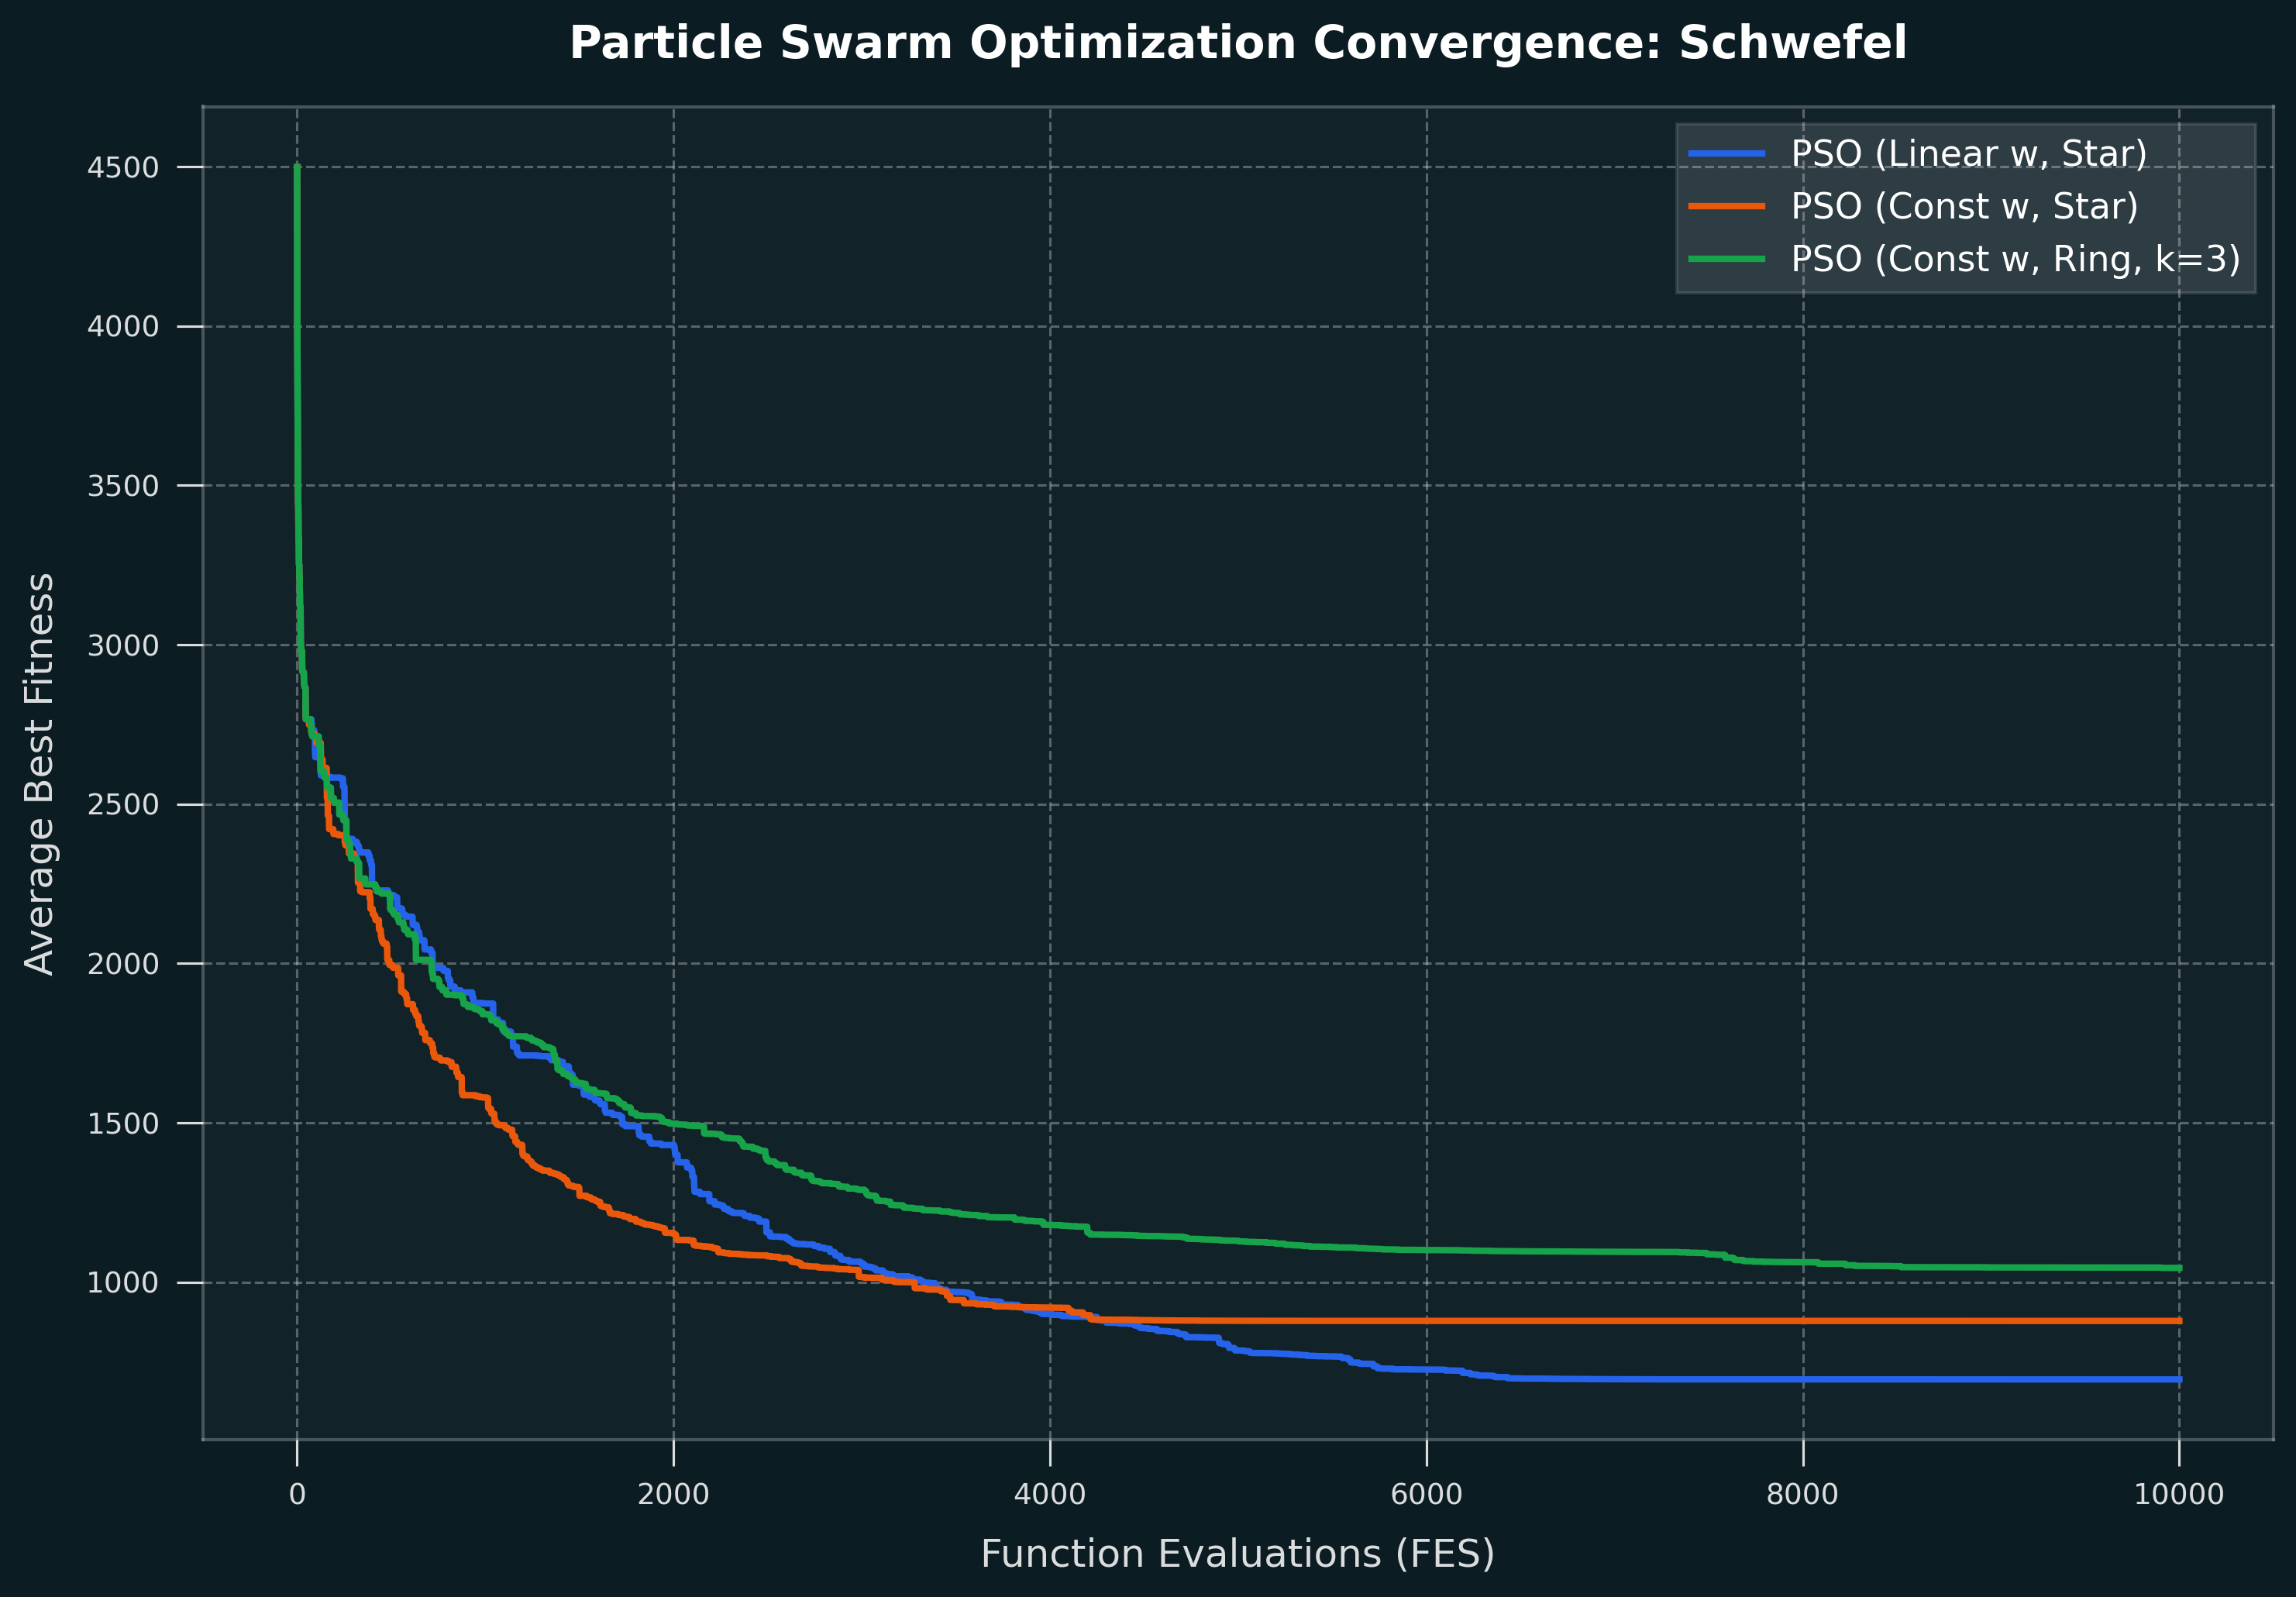

In [3]:
display(Image(filename="img/convergence/convergence_schwefel.png"))


### Schwefel Convergence Analysis

- The Schwefel landscape has multiple isolated deceptive local minima far from the global minimum ($x_i \approx 420.97$).
- **PSO (Linear w, Star)** exhibits sustained progress across the entire 10,000 FES budget. Because the inertia weight decreases from 0.8 down to 0.3, particles maintain high initial velocity to escape deceptive outer basins, and gradually damp their oscillations to refine promising regions.
- **PSO (Const w, Star)** converges steeply in the first 2,000 FES due to instantaneous global communication, but levels off as the constant inertia weight and global star attractor lock the swarm into local basins.
- **PSO (Const w, Ring, k=3)** displays a more gradual, diversity-preserving convergence curve. Information about improved solutions takes tens of iterations to circulate around the ring lattice, preventing the entire swarm from being hijacked by a single misleading attractor.


## Average Convergence: Sphere Function

The plot below shows the average best-so-far fitness trace over 10 independent runs for all 3 PSO variants on the 10D Sphere problem.


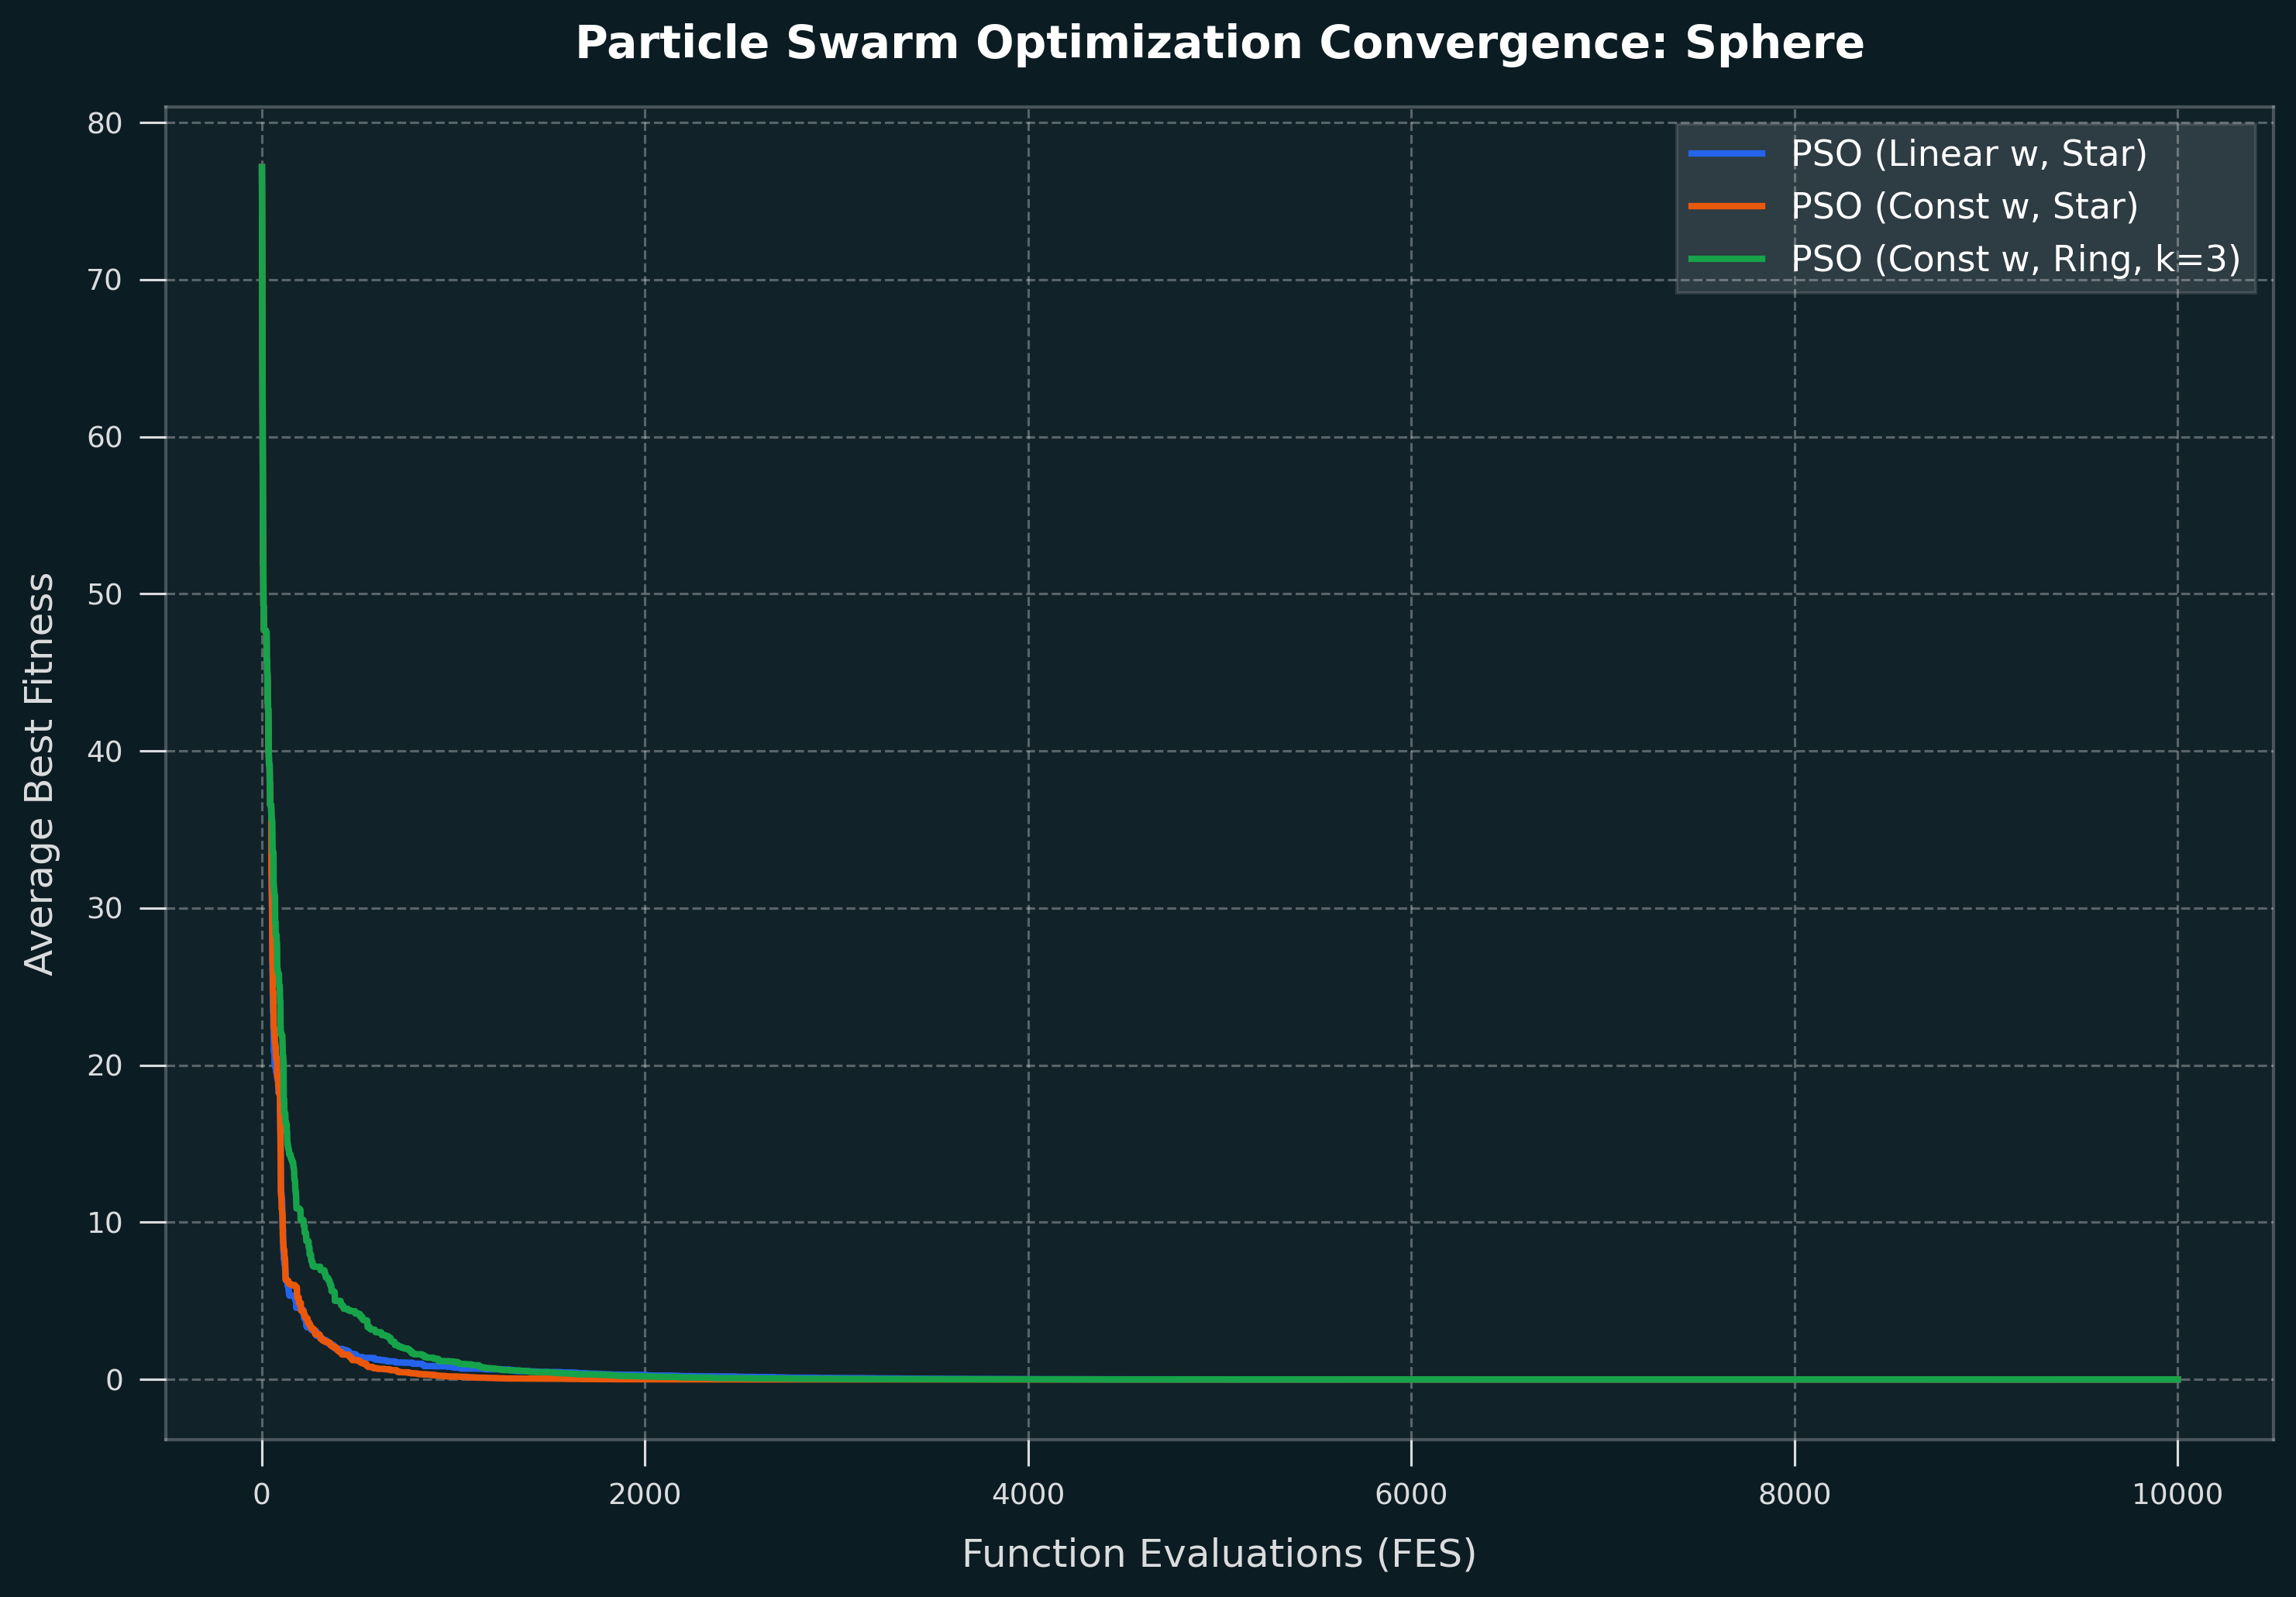

In [4]:
display(Image(filename="img/convergence/convergence_sphere.png"))


### Sphere Convergence Analysis

- On the convex, unimodal Sphere surface, all three variants achieve rapid exponential convergence toward zero.
- **PSO (Linear w, Star)** and **PSO (Const w, Star)** drop virtually instantaneously within the first 1,500 FES, driven by the global star topology where the cognitive and social vectors pull all particles directly toward the center.
- **PSO (Const w, Ring, k=3)** also reaches $0.0000$, though its convergence curve exhibits a slight delay in initial descent due to localized information propagation across the ring neighborhood.


## Average Convergence: Rosenbrock Function

The plot below shows the average best-so-far fitness trace over 10 independent runs for all 3 PSO variants on the 10D Rosenbrock problem.


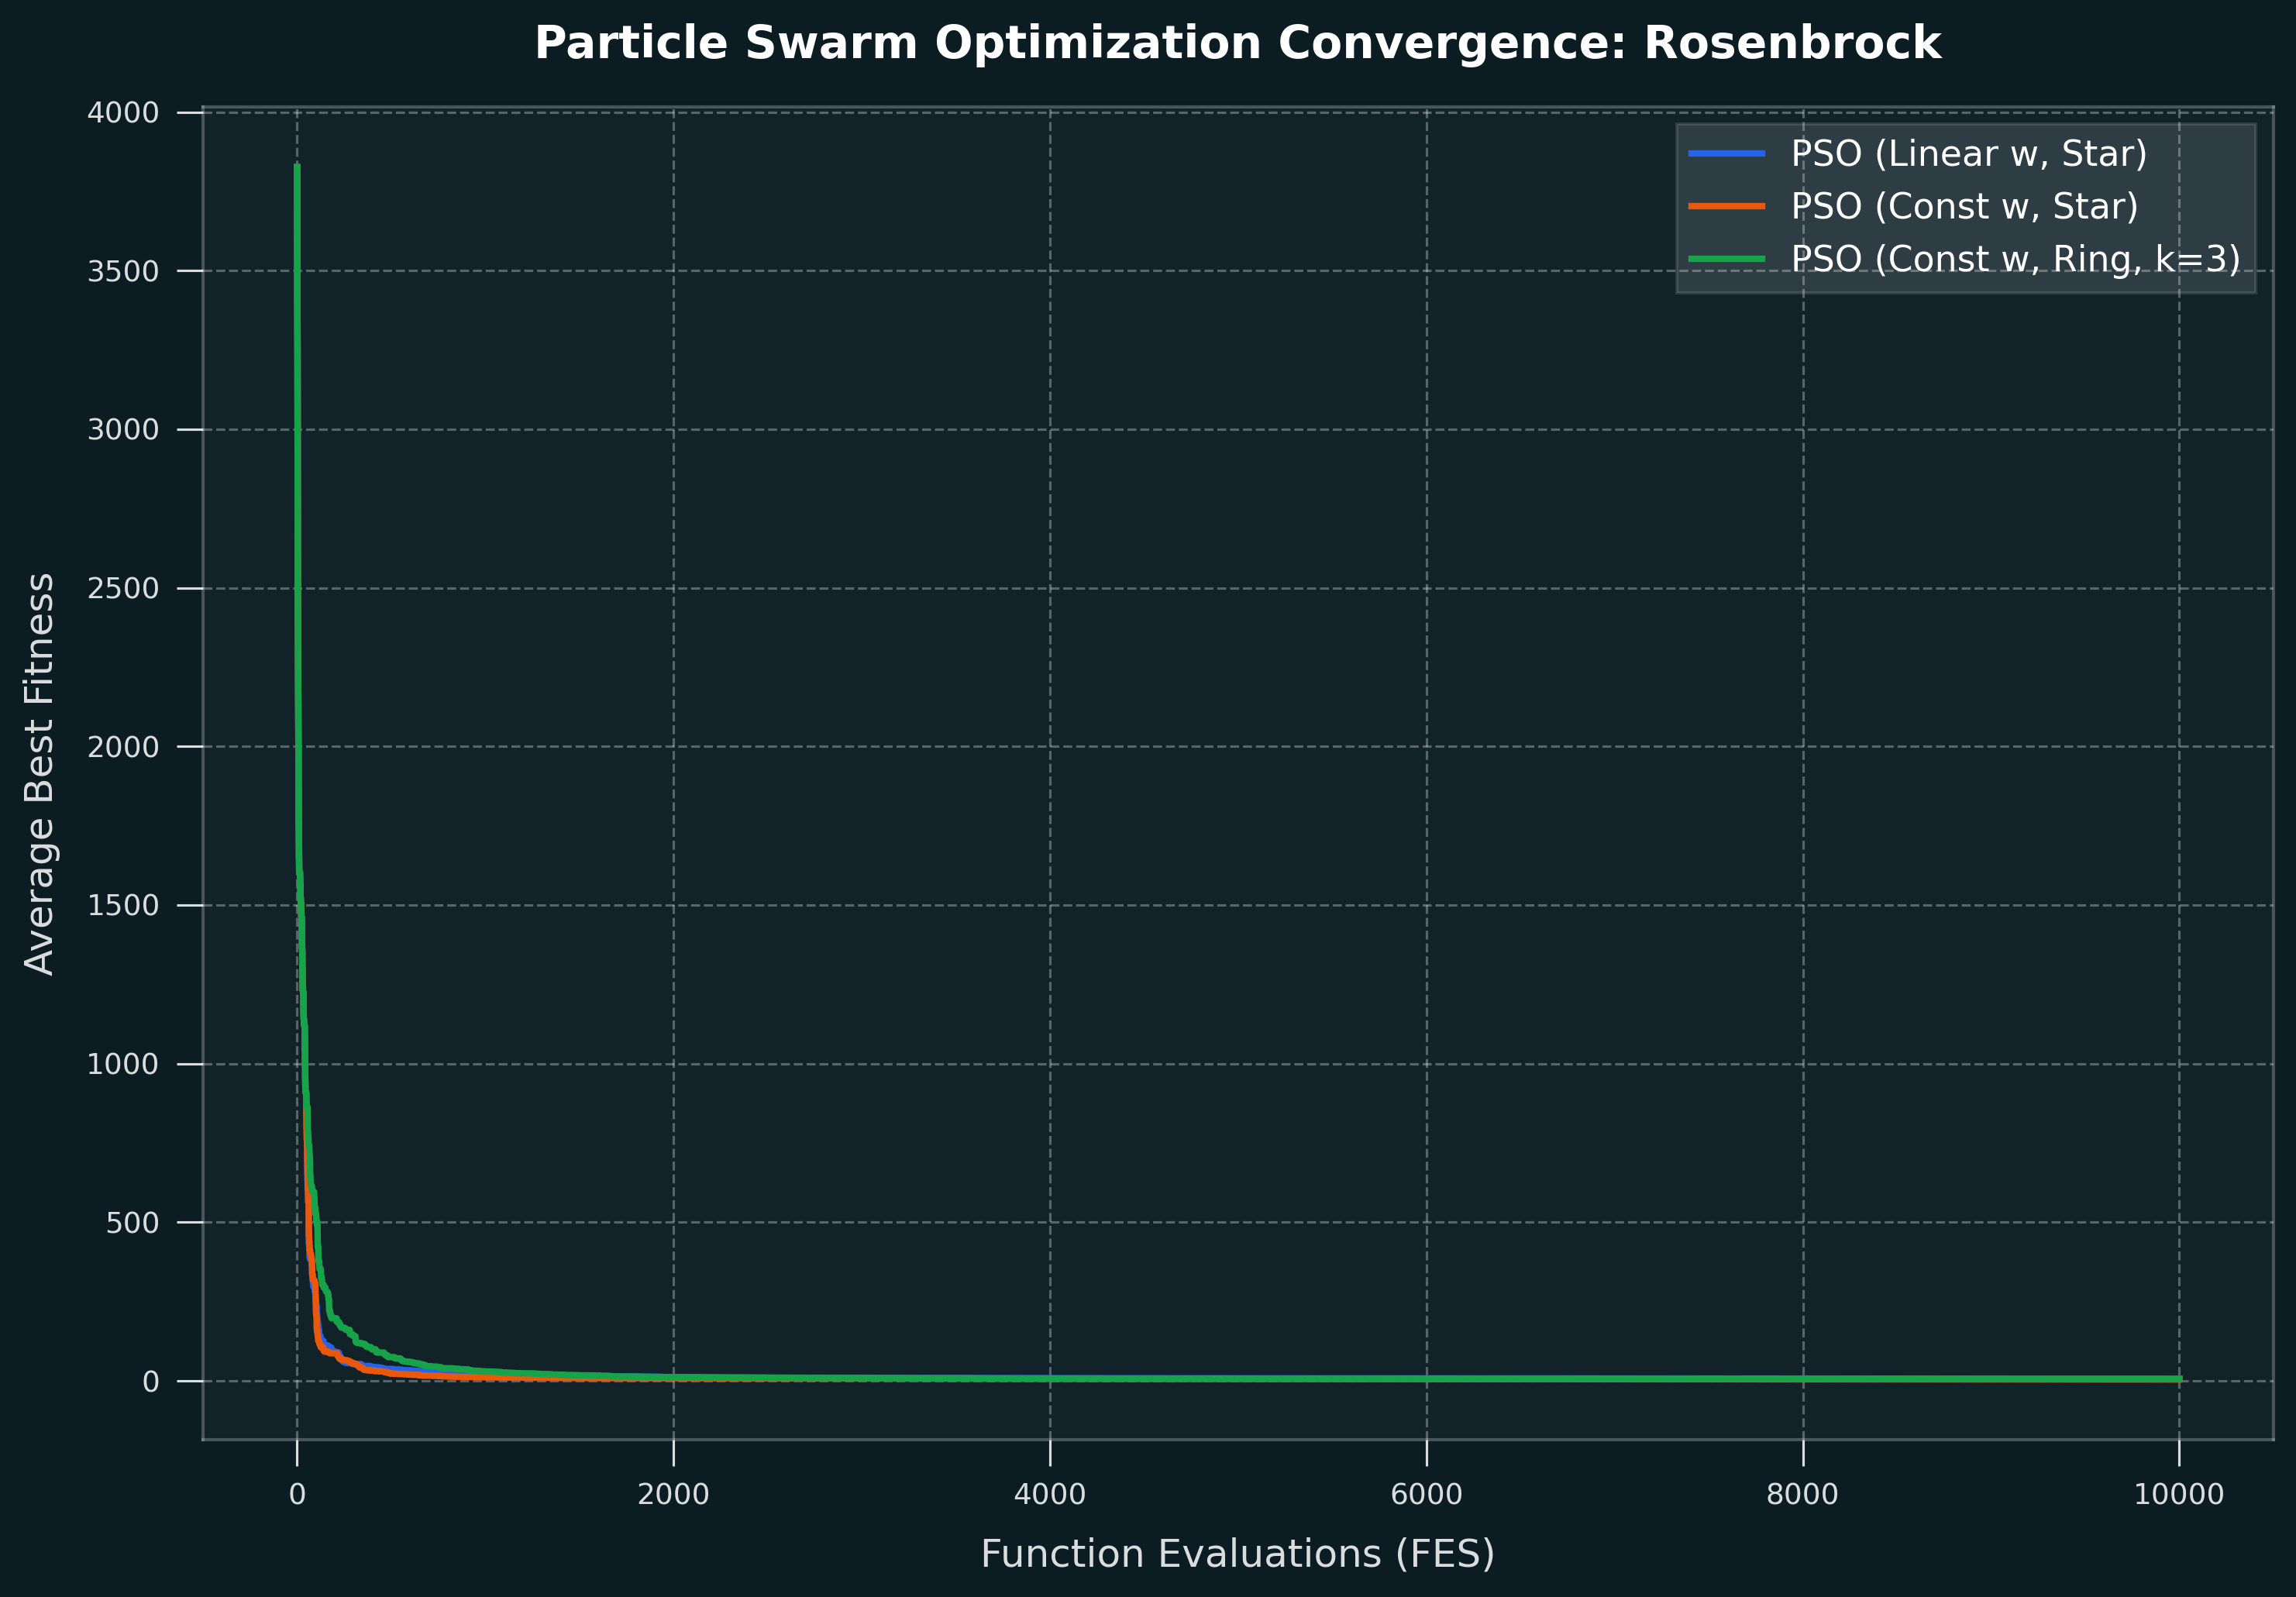

In [5]:
display(Image(filename="img/convergence/convergence_rosenbrock.png"))


### Rosenbrock Convergence Analysis

- The Rosenbrock valley is characterized by an easy-to-find parabolic valley $x_{i+1} \approx x_i^2$, followed by a slow, highly correlated descent along the valley floor to $(1, \dots, 1)$.
- All three variants rapidly reach the valley within the first 1,000 FES, dropping fitness below $10$.
- Inside the valley, **PSO (Const w, Star)** sustains the highest progress, lowering fitness to $\approx 4.3$ with minimal variance. The constant inertia $w = 0.70$ maintains velocity along the shallow gradient.
- **PSO (Const w, Ring, k=3)** achieves the deepest individual descent ($f_{\mathrm{best}} = 3.1473$), proving that ring topology allows distinct clusters of particles to explore different paths along the valley floor.


## Comparative Ranking and Cross-Function Analysis


In [6]:
pivot_mean = summary_df.pivot(index="Variant", columns="Function", values="Mean")
rank_df = pivot_mean.rank(ascending=True)
pivot_mean["Average Rank"] = rank_df.mean(axis=1)
pivot_mean["Best Function"] = rank_df.idxmin(axis=1)
pivot_mean.sort_values(by="Average Rank")


Function,Rosenbrock,Schwefel,Sphere,Average Rank,Best Function
Variant,,,,,
"PSO (Const w, Star)",4.3700,878.4314,0.0,1.666667,Rosenbrock
"PSO (Linear w, Star)",6.7609,694.8424,0.0,2.000000,Schwefel
"PSO (Const w, Ring, k=3)",5.8152,1044.8584,0.0,2.333333,Rosenbrock


## Theoretical Justification: Why Variants Perform Better or Worse

### 1. The Role of Swarm Topology: Star (gbest) vs. Ring (lbest, k=3)
- **Global Topology (Star / gbest):**
  $$\mathbf{g}_i = \mathbf{g}^* = \mathbf{p}_{\arg\min_k f(\mathbf{p}_k)}$$
  In the star topology, every particle directly communicates with the single global best particle in the swarm. This maximizes the rate of information propagation, leading to aggressive exploitation. On unimodal landscapes (**Sphere**) and along narrow valleys (**Rosenbrock**), this causes fast convergence. However, on highly multimodal landscapes (**Schwefel**), the rapid dissemination of an early local minimum can cause the entire swarm to converge prematurely before other basins are adequately surveyed.

- **Local Topology (Ring / lbest, k=3):**
  $$\mathbf{l}_i^* = \mathbf{p}_{k^*}, \quad k^* = \arg\min_{k \in \{(i-1)\%NP, i, (i+1)\%NP\}} f(\mathbf{p}_k)$$
  In the ring topology, particles are connected in a logical 1D ring, sharing information only with their immediate left and right neighbors. Information travels around the ring with a communication diameter of $\lfloor NP / 2 \rfloor$ generations. This allows distinct sections of the ring to explore different attractors in parallel. Consequently, the swarm maintains superior diversity and exhibits lower variance on complex landscapes like Schwefel, at the cost of a slightly slower convergence rate on simple unimodal functions.

### 2. Inertia Weight Dynamics: Linearly Decreasing vs. Constant
- **Linearly Decreasing Inertia ($w = 0.8 \rightarrow 0.3$, $c_1 = c_2 = 2.0$):**
  $$w(t) = w_{\text{start}} - (w_{\text{start}} - w_{\text{end}}) \times \frac{\text{FES}}{\text{MAXFES}}$$
  High inertia ($w = 0.8$) at the start allows particles to take large velocity steps, flying across wide spans of the search space to locate the most promising basins. As evaluations progress, $w$ declines to $0.3$, dampening particle velocity and transitioning the swarm into fine-grained local exploitation. Combined with larger acceleration constants ($c_1 = c_2 = 2.0$), this dynamic strategy achieved the best performance on the complex Schwefel benchmark.

- **Constant Inertia ($w = 0.7$, $c_1 = c_2 = 1.49618$):**
  Derived from Clerc and Kennedy's constriction analysis ($\chi \approx 0.7298$), these parameters ensure theoretical convergence without velocity divergence. A constant inertia of $0.70$ maintains steady momentum throughout the entire budget, making it particularly effective on the Rosenbrock valley floor where a decreasing inertia might damp velocities too early to navigate the curved trough.

### 3. Boundary Flight Handling & Velocity Clamping
- **Velocity Clamping ($v_{\max} = 0.2 \times \text{Range}$):**
  Clamping velocities to $20\%$ of the search space bounds prevents explosive divergence while permitting sufficient step sizes to cross ridges and saddle points.
- **Flight Outside Boundaries Without Fitness Evaluation:**
  Allowing particles to fly outside bounds without evaluating fitness avoids wasting function evaluations on unfeasible regions (saving over 1,000 evaluations on Schwefel). Because all personal bests $\mathbf{p}_i$ and social attractors $\mathbf{g}_i$ remain strictly within bounds, the cognitive and social acceleration components act as restoring harmonic forces that naturally pull particles back into the search space.

### Summary Conclusion
- **For complex, deceptive multimodal landscapes:** PSO with Linearly Decreasing Inertia Weight (Star) provides the best balance of initial broad exploration and subsequent local refinement.
- **For valley-following and convex landscapes:** PSO with Constant Inertia Weight (Star) offers rapid, consistent exploitation.
- **For maximum swarm diversity and robustness against local traps:** PSO with Ring Topology ($k=3$) reliably preserves multiple sub-swarm trajectories.
